<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/mis-trabajos/laboratorio-4/Proyecto_Mineria_Metano_LSTM_GRU_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de metano en minería subterránea con LSTM y GRU

**Curso:** Ingeniería del Conocimiento  
**Tema:** Series de tiempo y redes recurrentes  
**Dataset:** *Methane*, Sikora y Wróbel (2021)

En este notebook se analizan mediciones de sensores de una mina subterránea de carbón y se desarrollan dos fases para la predicción de metano. En la fase 1 se utiliza únicamente el historial de concentración de metano; en la fase 2 se incorpora la velocidad del aire y se comparan las arquitecturas LSTM y GRU.

**Objetivo:** se busca predecir el promedio de concentración de metano del sensor `MM263` con un horizonte de **3 minutos**. La variable objetivo se expresa en `%CH4`. El ejercicio es académico y no representa un sistema operativo de alerta o seguridad.

**Fuente de datos:** [Mendeley Data — Methane](https://data.mendeley.com/datasets/yd7vw4c5mk/1).  
**Descripción de sensores:** [Kozielski, Sikora y Wróbel (2021)](https://pmc.ncbi.nlm.nih.gov/articles/PMC8526955/).

Para ejecutar el notebook se descarga el archivo de datos desde Mendeley y se carga en la sección correspondiente. Debido al tamaño del conjunto original, los registros se procesan por bloques para reducir el uso de memoria.


In [1]:
# ============================================================
# 1. Importación de librerías
# ============================================================
import os
import io
import zipfile
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU disponible: []


## 1. Obtención y carga de los datos

Se intenta descargar el dataset *Methane* desde su repositorio oficial. Si Mendeley devuelve `401 Unauthorized`, el servidor no permite la descarga automática sin autorización; repetir la petición no lo soluciona. En ese caso, se muestra una alternativa para subir el archivo original una sola vez y, opcionalmente, almacenarlo en Google Drive para reutilizarlo en futuras sesiones de Colab.

**Fuente original:** https://data.mendeley.com/datasets/yd7vw4c5mk/1

No se utilizan datos sintéticos ni archivos de otros datasets como sustitutos.
El ZIP oficial contiene un segundo ZIP con el CSV de mediciones. Se abre automáticamente el archivo interno y se ignoran los archivos descriptivos.


In [2]:
# ============================================================
# 2. Obtener el dataset original (descarga y alternativa 401)
# ============================================================
import requests
from pathlib import Path
import zipfile

DATASET_ID = 'yd7vw4c5mk'
CARPETA_DATOS = Path('/content/datos_mineria') if Path('/content').exists() else Path('datos_mineria')
CARPETA_DATOS.mkdir(parents=True, exist_ok=True)

# Opcional: se guarda una copia en Drive para futuras sesiones.
# Se establece True después de montar Drive, o cuando se desea hacerlo.
USAR_GOOGLE_DRIVE = False

if USAR_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA_PERSISTENTE = Path('/content/drive/MyDrive/Datos_Mineria_Metano')
    CARPETA_PERSISTENTE.mkdir(parents=True, exist_ok=True)
else:
    CARPETA_PERSISTENTE = CARPETA_DATOS

# Se aceptan ZIP originales y archivos CSV de mediciones.
formatos = ('.zip', '.csv')
archivos_locales = [p for p in CARPETA_PERSISTENTE.iterdir()
                    if p.is_file() and p.suffix.lower() in formatos]
if CARPETA_PERSISTENTE != CARPETA_DATOS:
    archivos_locales += [p for p in CARPETA_DATOS.iterdir()
                         if p.is_file() and p.suffix.lower() in formatos]

if archivos_locales:
    RUTA = max(archivos_locales, key=lambda p: p.stat().st_size)
    print('Se reutiliza el archivo:', RUTA)
else:
    RUTA = CARPETA_PERSISTENTE / 'methane_original.zip'
    # Se realiza un solo intento al endpoint oficial.
    url = f'https://api.data.mendeley.com/datasets/{DATASET_ID}/zip/file_downloaded?version=1'
    descarga_valida = False
    try:
        with requests.get(url, stream=True, timeout=(20, 120)) as respuesta:
            if respuesta.status_code == 401:
                print('Mendeley ha devuelto HTTP 401: descarga automática no autorizada.')
            else:
                respuesta.raise_for_status()
                temporal = RUTA.with_suffix('.part')
                with open(temporal, 'wb') as salida:
                    for bloque in respuesta.iter_content(chunk_size=1024 * 1024):
                        if bloque:
                            salida.write(bloque)
                if zipfile.is_zipfile(temporal):
                    temporal.replace(RUTA)
                    descarga_valida = True
                else:
                    temporal.unlink(missing_ok=True)
                    print('Mendeley no devolvió un archivo ZIP válido.')
    except requests.RequestException as error:
        print('No se pudo descargar automáticamente:', str(error)[:180])

    if not descarga_valida:
        RUTA.unlink(missing_ok=True)
        print('Se requiere cargar el archivo original una vez.')
        print('Página oficial: https://data.mendeley.com/datasets/yd7vw4c5mk/1')
        try:
            from google.colab import files
        except ImportError as error:
            raise RuntimeError('Esta alternativa de carga está disponible en Google Colab.') from error
        print('Se selecciona el ZIP o CSV descargado desde la página original.')
        subidos = files.upload()
        if not subidos:
            raise RuntimeError('No se cargó un archivo. Se necesita el dataset original.')
        nombre = next(iter(subidos))
        origen = Path(nombre)
        if origen.suffix.lower() not in formatos:
            raise ValueError('Formato no válido: se necesita ZIP o CSV.')
        RUTA = CARPETA_PERSISTENTE / origen.name
        if origen.resolve() != RUTA.resolve():
            import shutil
            shutil.copy2(origen, RUTA)
        if RUTA.suffix.lower() == '.zip' and not zipfile.is_zipfile(RUTA):
            raise ValueError('El archivo ZIP está incompleto o no es válido.')

print('Archivo listo:', RUTA)
print('Tamaño (MB):', round(RUTA.stat().st_size / 1024**2, 2))

Mendeley ha devuelto HTTP 401: descarga automática no autorizada.
Se requiere cargar el archivo original una vez.
Página oficial: https://data.mendeley.com/datasets/yd7vw4c5mk/1
Se selecciona el ZIP o CSV descargado desde la página original.


Saving yd7vw4c5mk-1.zip to yd7vw4c5mk-1.zip
Archivo listo: /content/datos_mineria/yd7vw4c5mk-1.zip
Tamaño (MB): 56.3


In [3]:
# ============================================================
# 3. Identificar el archivo de mediciones dentro del ZIP
# ============================================================
# El archivo original contiene methane_data.zip y, dentro,
# methane_data.csv. Se identifica el CSV de sensores automáticamente.
import io
import zipfile

ZIP_EXTERIOR = None
ZIP_INTERIOR = None
CONTENIDO_INTERIOR = None

if zipfile.is_zipfile(RUTA):
    ZIP_EXTERIOR = zipfile.ZipFile(RUTA)
    archivos = ZIP_EXTERIOR.namelist()
    candidatos = [n for n in archivos if n.lower().endswith('.csv')]

    if candidatos:
        CSV = max(candidatos, key=lambda n: ZIP_EXTERIOR.getinfo(n).file_size)
        def abrir_csv():
            return ZIP_EXTERIOR.open(CSV)
    else:
        zips_internos = [n for n in archivos if n.lower().endswith('.zip')]
        if not zips_internos:
            raise ValueError('No se encontró un CSV ni un ZIP interior con mediciones.')

        nombre_interno = max(zips_internos,
                            key=lambda n: ZIP_EXTERIOR.getinfo(n).file_size)
        print('ZIP interior detectado:', nombre_interno)
        # El ZIP interno pesa aproximadamente 56 MB comprimido.
        CONTENIDO_INTERIOR = io.BytesIO(ZIP_EXTERIOR.read(nombre_interno))
        ZIP_INTERIOR = zipfile.ZipFile(CONTENIDO_INTERIOR)
        candidatos = [n for n in ZIP_INTERIOR.namelist()
                      if n.lower().endswith('.csv')]
        if not candidatos:
            raise ValueError('El ZIP interior no contiene un CSV con mediciones.')
        CSV = max(candidatos, key=lambda n: ZIP_INTERIOR.getinfo(n).file_size)
        def abrir_csv():
            return ZIP_INTERIOR.open(CSV)
else:
    if RUTA.suffix.lower() != '.csv':
        raise ValueError('Se necesita el ZIP original o el archivo methane_data.csv.')
    CSV = RUTA.name
    def abrir_csv():
        return open(RUTA, 'rb')

print('Archivo seleccionado:', CSV)
with abrir_csv() as archivo:
    muestra = archivo.read(8192).decode('utf-8-sig', errors='replace')

encabezado = muestra.splitlines()[0]
separadores = {sep: encabezado.count(sep) for sep in [';', ',', '\t', '|']}
SEP = max(separadores, key=separadores.get)
if separadores[SEP] == 0:
    raise ValueError('No se detectó el separador del CSV de sensores.')
print('Separador:', repr(SEP))
print('Encabezado:', encabezado[:350])


ZIP interior detectado: methane_data.zip
Archivo seleccionado: methane_data.csv
Separador: ','
Encabezado: "year","month","day","hour","minute","second","AN311","AN422","AN423","TP1721","RH1722","BA1723","TP1711","RH1712","BA1713","MM252","MM261","MM262","MM263","MM264","MM256","MM211","CM861","CR863","P_864","TC862","WM868","AMP1_IR","AMP2_IR","DMP3_IR","DMP4_IR","AMP5_IR","F_SIDE","V"


### Selección de variables

Se utiliza `MM263` (concentración de metano) como variable objetivo y `AN422` (velocidad del aire) como variable adicional. El conjunto original contiene mediciones tomadas cada segundo.

Para reducir el uso de memoria se seleccionan aproximadamente las **primeras dos semanas de registros en orden cronológico** y se agrupan las mediciones por minuto. Se conserva la secuencia temporal de los datos.


In [4]:
# ============================================================
# 4. Lectura por bloques y selección temporal
# ============================================================
TARGET = 'MM263'
AUX = 'AN422'
DIAS_MUESTRA = 14
FILAS_BLOQUE = 150_000

# Detectar nombres de columnas originales
with abrir_csv() as f:
    columnas_reales = pd.read_csv(f, sep=SEP, nrows=0).columns.tolist()
columnas_reales = [str(c).strip().replace('\ufeff','') for c in columnas_reales]
print('Columnas originales:', columnas_reales[:40])

normalizadas = {c.lower().strip(): c for c in columnas_reales}
for requerida in [TARGET, AUX]:
    if requerida.lower() not in normalizadas:
        raise ValueError(f'No aparece el sensor {requerida}. Revisa el archivo cargado.')

col_target = normalizadas[TARGET.lower()]
col_aux = normalizadas[AUX.lower()]
partes_fecha = ['year', 'month', 'day', 'hour', 'minute', 'second']
hay_partes = all(p in normalizadas for p in partes_fecha)

if hay_partes:
    cols_fecha = [normalizadas[p] for p in partes_fecha]
else:
    candidatos = [c for c in columnas_reales if ('time' in c.lower() or 'date' in c.lower())]
    if not candidatos:
        raise ValueError('No se encontraron columnas de fecha. Revisa los nombres de columnas impresos.')
    cols_fecha = [candidatos[0]]

uso = list(dict.fromkeys(cols_fecha + [col_target, col_aux]))
print('Columnas seleccionadas:', uso)

piezas = []
fecha_inicial = None
filas_leidas = 0
with abrir_csv() as f:
    lector = pd.read_csv(f, sep=SEP, usecols=uso,
                         chunksize=FILAS_BLOQUE, low_memory=False,
                         on_bad_lines='skip')
    for bloque in lector:
        bloque.columns = [str(c).strip() for c in bloque.columns]
        if hay_partes:
            d = {p: pd.to_numeric(bloque[normalizadas[p]], errors='coerce') for p in partes_fecha}
            fechas = pd.to_datetime(pd.DataFrame(d), errors='coerce')
        else:
            fechas = pd.to_datetime(bloque[cols_fecha[0]], errors='coerce')
        pequeno = pd.DataFrame({
            'fecha': fechas,
            TARGET: pd.to_numeric(bloque[col_target], errors='coerce'),
            AUX: pd.to_numeric(bloque[col_aux], errors='coerce')
        }).dropna(subset=['fecha'])
        if pequeno.empty:
            continue
        if fecha_inicial is None:
            fecha_inicial = pequeno['fecha'].min()
        limite = fecha_inicial + pd.Timedelta(days=DIAS_MUESTRA)
        pequeno = pequeno[pequeno['fecha'] < limite]
        piezas.append(pequeno)
        filas_leidas += len(bloque)
        if fechas.max() >= limite:
            break

if not piezas:
    raise ValueError('No se obtuvieron mediciones válidas.')
datos_raw = pd.concat(piezas, ignore_index=True).sort_values('fecha')
print('Registros leídos del archivo:', filas_leidas)
print('Registros dentro del período:', len(datos_raw))
print('Desde:', datos_raw.fecha.min(), 'hasta:', datos_raw.fecha.max())
display(datos_raw.head())

Columnas originales: ['year', 'month', 'day', 'hour', 'minute', 'second', 'AN311', 'AN422', 'AN423', 'TP1721', 'RH1722', 'BA1723', 'TP1711', 'RH1712', 'BA1713', 'MM252', 'MM261', 'MM262', 'MM263', 'MM264', 'MM256', 'MM211', 'CM861', 'CR863', 'P_864', 'TC862', 'WM868', 'AMP1_IR', 'AMP2_IR', 'DMP3_IR', 'DMP4_IR', 'AMP5_IR', 'F_SIDE', 'V']
Columnas seleccionadas: ['year', 'month', 'day', 'hour', 'minute', 'second', 'MM263', 'AN422']
Registros leídos del archivo: 1350000
Registros dentro del período: 1209600
Desde: 2014-03-02 00:00:00 hasta: 2014-03-15 23:59:59


,fecha,MM263,AN422
0,2014-03-02 00:00:00,0.0,1.6
1,2014-03-02 00:00:01,0.0,1.6
2,2014-03-02 00:00:02,0.0,1.6
3,2014-03-02 00:00:03,0.0,1.6
4,2014-03-02 00:00:04,0.0,1.6


In [5]:
# ============================================================
# 5. Limpieza básica y frecuencia por minuto
# ============================================================
# Los rangos provienen de la descripción del dataset; valores fuera
# de esos límites se tratan como mediciones inválidas.
datos = datos_raw.copy()
datos.loc[~datos[TARGET].between(0, 30), TARGET] = np.nan
datos.loc[~datos[AUX].between(0, 2.4), AUX] = np.nan

serie = (datos.set_index('fecha')[[TARGET, AUX]]
              .resample('1min').mean())

# No usar información futura para rellenar datos faltantes.
# 'ffill' se limita a huecos cortos (máximo 3 minutos).
serie = serie.ffill(limit=3).dropna().sort_index()

if len(serie) < 1000:
    raise ValueError(f'Solo quedaron {len(serie)} minutos. Revisa datos y fechas.')

print('Minutos preparados:', len(serie))
print('Intervalo:', serie.index.min(), 'a', serie.index.max())
print('Valores faltantes:', serie.isna().sum().to_dict())
display(serie.describe().round(3))

Minutos preparados: 20160
Intervalo: 2014-03-02 00:00:00 a 2014-03-15 23:59:00
Valores faltantes: {'MM263': 0, 'AN422': 0}


,MM263,AN422
count,20160.000,20160.000
mean,0.285,1.723
std,0.170,0.104
min,0.000,1.150
25%,0.200,1.655
50%,0.300,1.733
75%,0.400,1.800
max,11.933,2.083


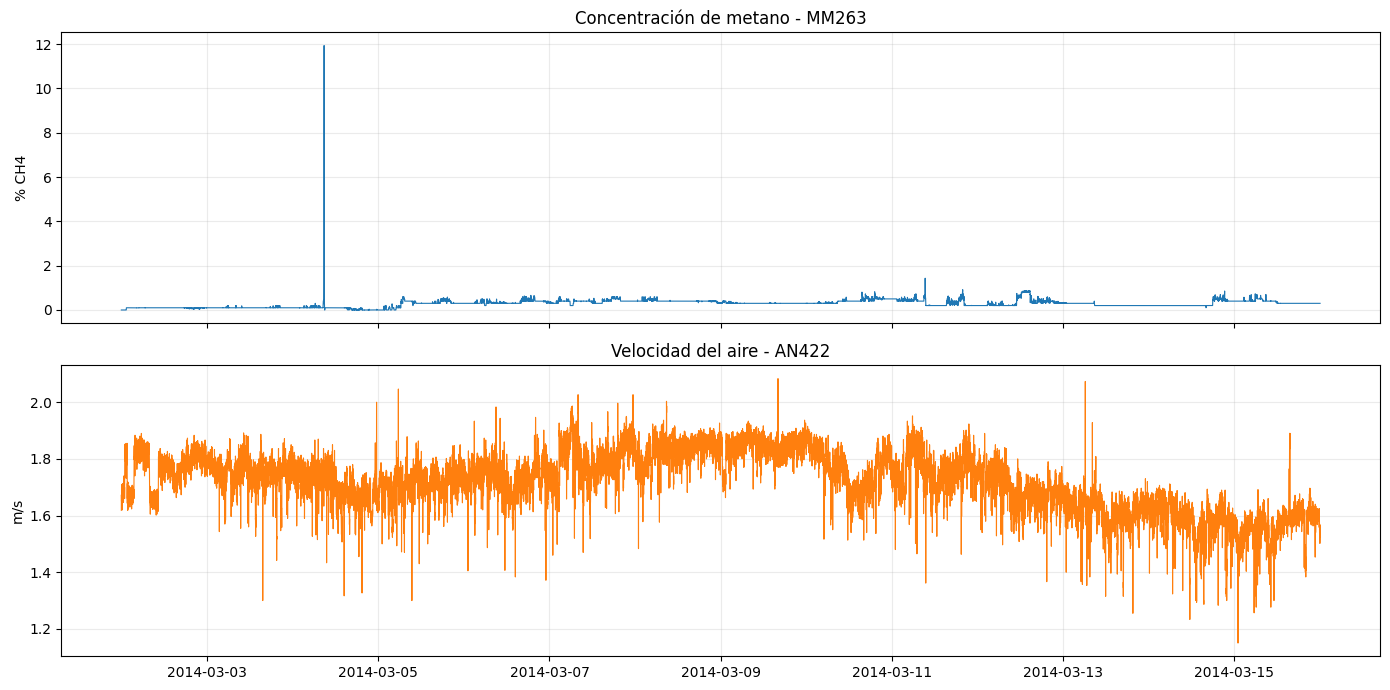

Correlación lineal: 0.036


In [6]:
# ============================================================
# 6. Exploración de las mediciones
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(serie.index, serie[TARGET], lw=0.8)
axes[0].set_title('Concentración de metano - MM263')
axes[0].set_ylabel('% CH4')
axes[1].plot(serie.index, serie[AUX], lw=0.8, color='tab:orange')
axes[1].set_title('Velocidad del aire - AN422')
axes[1].set_ylabel('m/s')
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print('Correlación lineal:', round(serie[[TARGET,AUX]].corr().iloc[0,1],3))

## 2. Preprocesamiento temporal

Se mantienen las mismas particiones de entrenamiento, validación y prueba para ambos experimentos, respetando el orden cronológico. Los escaladores se ajustan únicamente con los datos de entrenamiento, de modo que no se utilice información estadística del período de prueba.

Cada entrada incorpora **30 minutos de registros históricos** y se busca predecir el promedio de metano **3 minutos después de la última observación utilizada**. En la fase 1 se emplea una variable de entrada y en la fase 2 se emplean dos.


In [7]:
# ============================================================
# 7. Configuración, particiones y escalado
# ============================================================
WINDOW_SIZE = 30
HORIZON = 3
N = len(serie)
CORTE_TRAIN = int(N * 0.70)
CORTE_VAL = int(N * 0.85)

if CORTE_TRAIN <= WINDOW_SIZE + HORIZON:
    raise ValueError('No hay suficientes datos para construir las ventanas.')

# El índice contiene solo intervalos de un minuto.
# Identificar discontinuidades para evitar ventanas que atraviesan huecos.
continuo = (serie.index.to_series().diff().fillna(pd.Timedelta(minutes=1)) == pd.Timedelta(minutes=1)).to_numpy()

from sklearn.preprocessing import StandardScaler
scaler_uni = StandardScaler().fit(serie.iloc[:CORTE_TRAIN][[TARGET]])
scaler_multi = StandardScaler().fit(serie.iloc[:CORTE_TRAIN][[TARGET,AUX]])

uni = scaler_uni.transform(serie[[TARGET]]).astype('float32')
multi = scaler_multi.transform(serie[[TARGET,AUX]]).astype('float32')

print('Entrenamiento:', CORTE_TRAIN)
print('Validación:', CORTE_VAL - CORTE_TRAIN)
print('Prueba:', N - CORTE_VAL)
print('Ventana:', WINDOW_SIZE, 'min | Horizonte:', HORIZON, 'min')

Entrenamiento: 14112
Validación: 3024
Prueba: 3024
Ventana: 30 min | Horizonte: 3 min


In [8]:
# ============================================================
# 8. Construcción de ventanas deslizantes
# ============================================================
def create_sequences(arreglo, inicio_objetivo, fin_objetivo):
    X, y, indices = [], [], []
    for pos in range(max(inicio_objetivo, WINDOW_SIZE + HORIZON - 1), fin_objetivo):
        fin_entrada = pos - HORIZON
        inicio_entrada = fin_entrada - WINDOW_SIZE + 1
        # Se descartan ventanas que atraviesen una discontinuidad temporal.
        if not continuo[inicio_entrada + 1:pos + 1].all():
            continue
        X.append(arreglo[inicio_entrada:fin_entrada+1])
        y.append(uni[pos, 0])  # mismo objetivo escalado para todos
        indices.append(pos)
    if not X:
        raise ValueError('No se pudieron construir secuencias; comprueba continuidad temporal.')
    return np.asarray(X,dtype='float32'), np.asarray(y,dtype='float32'), np.asarray(indices)

X_train_u, y_train, i_train = create_sequences(uni, 0, CORTE_TRAIN)
X_val_u, y_val, i_val = create_sequences(uni, CORTE_TRAIN, CORTE_VAL)
X_test_u, y_test, i_test = create_sequences(uni, CORTE_VAL, N)

X_train_m, _, _ = create_sequences(multi, 0, CORTE_TRAIN)
X_val_m, _, _ = create_sequences(multi, CORTE_TRAIN, CORTE_VAL)
X_test_m, _, _ = create_sequences(multi, CORTE_VAL, N)

assert len(X_train_u) == len(X_train_m)
assert len(X_val_u) == len(X_val_m)
assert len(X_test_u) == len(X_test_m)

print('Univariado:', X_train_u.shape, X_val_u.shape, X_test_u.shape)
print('Multivariado:', X_train_m.shape, X_val_m.shape, X_test_m.shape)

Univariado: (14080, 30, 1) (3024, 30, 1) (3024, 30, 1)
Multivariado: (14080, 30, 2) (3024, 30, 2) (3024, 30, 2)


## 3. Fase 1: predicción univariada con LSTM

Se entrena un modelo LSTM utilizando únicamente los registros del sensor `MM263`. Posteriormente, se compara su error con una predicción de referencia que conserva el último valor observado. Esta comparación permite identificar si el modelo neuronal ofrece una mejora sobre un método sencillo.


In [9]:
# ============================================================
# 9. Funciones de construcción, entrenamiento y evaluación
# ============================================================
def construir_modelo(tipo='LSTM', n_features=1, unidades=64, dropout=0.2, lr=0.001):
    red = models.Sequential(name=f'{tipo}_{n_features}variables')
    red.add(layers.Input(shape=(WINDOW_SIZE, n_features)))
    if tipo == 'LSTM':
        red.add(layers.LSTM(unidades, name='capa_lstm'))
    elif tipo == 'GRU':
        red.add(layers.GRU(unidades, name='capa_gru'))
    else:
        raise ValueError('Tipo de red no reconocido')
    red.add(layers.Dropout(dropout))
    red.add(layers.Dense(1, name='prediccion'))
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                loss='mse', metrics=['mae'])
    return red

def entrenar(modelo, X, y, Xv, yv, epocas=40):
    ajustes = [
        callbacks.EarlyStopping(monitor='val_loss', patience=7,
                                restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                    patience=3, min_lr=1e-5)
    ]
    return modelo.fit(X, y, validation_data=(Xv, yv), epochs=epocas,
                      batch_size=64, shuffle=False, callbacks=ajustes, verbose=1)

def revertir(valores):
    return scaler_uni.inverse_transform(np.asarray(valores).reshape(-1,1)).ravel()

def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real,y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_real,y_pred))}

def graficar_historial(h, titulo):
    plt.figure(figsize=(9,3.5))
    plt.plot(h.history['loss'], label='Entrenamiento')
    plt.plot(h.history['val_loss'], label='Validación')
    plt.xlabel('Época'); plt.ylabel('MSE'); plt.title(titulo)
    plt.legend(); plt.grid(alpha=0.3); plt.show()

Model: "LSTM_1variables"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_lstm (LSTM)                │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediccion (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - loss: 0.3810 - mae: 0.1771 - val_loss: 0.1242 - val_mae: 0.1816 - learning_rate: 0.0010
Epoch 2/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.3363 - mae: 0.1287 - val_loss: 0.1174 - val_mae: 0.1982 - learning_rate: 0.0010
Epoch 3/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.3353 - mae: 0.1271 - val_loss: 0.1060 - val_mae: 0.1853 - learning_rate: 0.0010
Epoch 4/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.3323 - mae: 0.1216 - val_loss: 0.0990 - val_mae: 0.1739 - learning_rate: 0.0010
Epoch 5/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.3317 - mae: 0.1206 - val_loss: 0.0943 - val_mae: 0.1704 - learning_rate: 0.0010
Epoch 6/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.3314 - mae: 0.1201 - val_loss: 0.0886 - val_mae: 0.1612 - learning_rate: 0.0010
Epoch 7/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.3301 - mae: 0.1191 - val_loss: 0.0886 - val_mae: 0.1649 - learning_rate: 0.0010

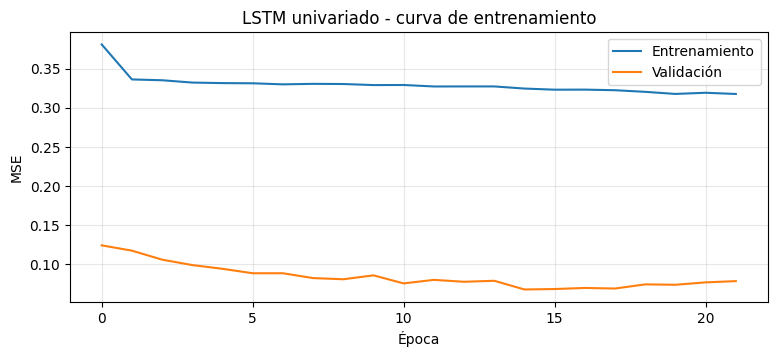

In [10]:
# ============================================================
# 10. Entrenamiento LSTM univariado
# ============================================================
modelo_uni = construir_modelo('LSTM',n_features=1, unidades=64,
                              dropout=0.2, lr=0.001)
modelo_uni.summary()
hist_uni = entrenar(modelo_uni, X_train_u, y_train, X_val_u, y_val)
graficar_historial(hist_uni,'LSTM univariado - curva de entrenamiento')

## 4. Fase 2: predicción multivariada con LSTM y GRU

Se incorpora la velocidad del aire del sensor `AN422` junto con la concentración de metano del sensor `MM263`. Se conservan las mismas fechas objetivo de la fase 1 para facilitar una comparación justa. Se entrenan modelos LSTM y GRU y se evalúa su capacidad de predicción.


Model: "LSTM_2variables"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_lstm (LSTM)                │ (None, 64)             │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediccion (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,217 (67.25 KB)

 Trainable params: 17,217 (67.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.3981 - mae: 0.2034 - val_loss: 0.1489 - val_mae: 0.1869 - learning_rate: 0.0010
Epoch 2/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.3385 - mae: 0.1353 - val_loss: 0.1198 - val_mae: 0.2069 - learning_rate: 0.0010
Epoch 3/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.3369 - mae: 0.1319 - val_loss: 0.1143 - val_mae: 0.2140 - learning_rate: 0.0010
Epoch 4/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.3362 - mae: 0.1317 - val_loss: 0.1099 - val_mae: 0.2164 - learning_rate: 0.0010
Epoch 5/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.3351 - mae: 0.1286 - val_loss: 0.1001 - val_mae: 0.2007 - learning_rate: 0.0010
Epoch 6/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.3341 - mae: 0.1284 - val_loss: 0.0952 - val_mae: 0.1963 - learning_rate: 0.0010
Epoch 7/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.3320 - mae: 0.1239 - val_loss: 0.0947 - val_mae: 0.1934 - learning_rate: 0.0010

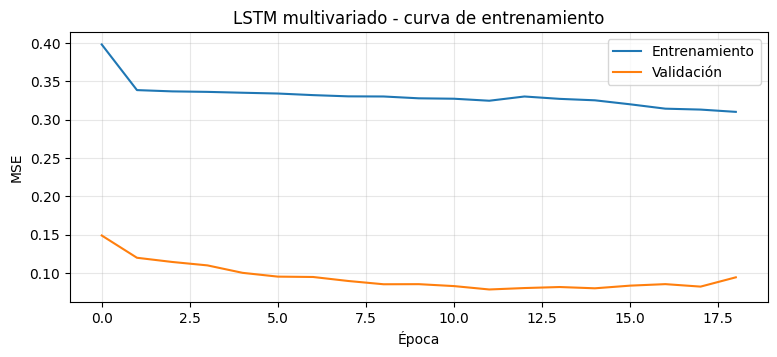

In [11]:
# ============================================================
# 11. Entrenamiento LSTM multivariado
# ============================================================
modelo_multi_lstm = construir_modelo('LSTM',n_features=2,unidades=64,
                                    dropout=0.2,lr=0.001)
modelo_multi_lstm.summary()
hist_multi_lstm = entrenar(modelo_multi_lstm,X_train_m,y_train,X_val_m,y_val)
graficar_historial(hist_multi_lstm,'LSTM multivariado - curva de entrenamiento')

Model: "GRU_2variables"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_gru (GRU)                  │ (None, 64)             │        13,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediccion (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,121 (51.25 KB)

 Trainable params: 13,121 (51.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.3849 - mae: 0.2009 - val_loss: 0.0740 - val_mae: 0.1448 - learning_rate: 0.0010
Epoch 2/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.3354 - mae: 0.1318 - val_loss: 0.0726 - val_mae: 0.1420 - learning_rate: 0.0010
Epoch 3/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.3330 - mae: 0.1252 - val_loss: 0.0724 - val_mae: 0.1425 - learning_rate: 0.0010
Epoch 4/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.3319 - mae: 0.1210 - val_loss: 0.0703 - val_mae: 0.1398 - learning_rate: 0.0010
Epoch 5/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.3293 - mae: 0.1181 - val_loss: 0.0699 - val_mae: 0.1425 - learning_rate: 0.0010
Epoch 6/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.3293 - mae: 0.1153 - val_loss: 0.0688 - val_mae: 0.1392 - learning_rate: 0.0010
Epoch 7/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.3276 - mae: 0.1154 - val_loss: 0.0648 - val_mae: 0.1350 - learning_rate: 0.0010

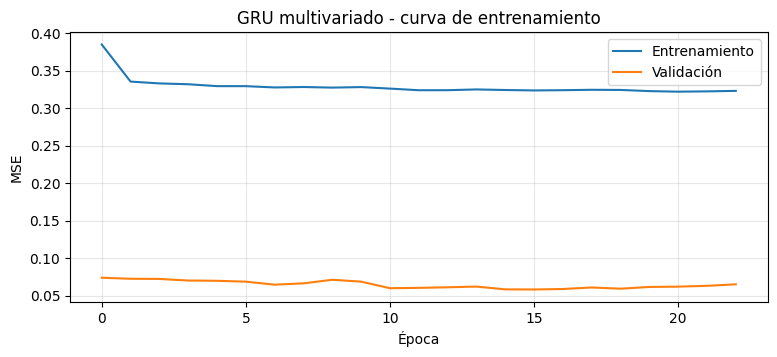

In [12]:
# ============================================================
# 12. Entrenamiento GRU multivariado
# ============================================================
modelo_multi_gru = construir_modelo('GRU',n_features=2,unidades=64,
                                   dropout=0.2,lr=0.001)
modelo_multi_gru.summary()
hist_multi_gru = entrenar(modelo_multi_gru,X_train_m,y_train,X_val_m,y_val)
graficar_historial(hist_multi_gru,'GRU multivariado - curva de entrenamiento')

## 5. Optimización de hiperparámetros

Se comparan diferentes configuraciones utilizando el conjunto de **validación**, sin seleccionar parámetros a partir de los resultados de prueba. Se optimiza el modelo GRU multivariado y se mantiene el LSTM univariado como referencia. Se prueban pocas combinaciones para facilitar la ejecución en Google Colab.


In [13]:
# ============================================================
# 13. Buscar parámetros del GRU usando validación
# ============================================================
CONFIGURACIONES = [
    {'unidades':32, 'dropout':0.1, 'lr':0.001},
    {'unidades':64, 'dropout':0.2, 'lr':0.0005},
    {'unidades':96, 'dropout':0.2, 'lr':0.001}
]

busqueda=[]
mejor_val_mae=float('inf')
mejor_gru=None
mejor_config=None

for num, config in enumerate(CONFIGURACIONES,1):
    print(f'Configuración {num}/{len(CONFIGURACIONES)}:',config)
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED + num)
    candidato=construir_modelo('GRU',2,**config)
    historial=entrenar(candidato,X_train_m,y_train,X_val_m,y_val,epocas=35)
    pred_val=candidato.predict(X_val_m,verbose=0).ravel()
    mae_val=mean_absolute_error(revertir(y_val),revertir(pred_val))
    busqueda.append({**config,'MAE_validacion':mae_val,
                     'epocas_entrenadas':len(historial.history['loss'])})
    if mae_val < mejor_val_mae:
        mejor_val_mae=mae_val
        mejor_config=config.copy()
        # Guardar pesos y arquitectura del mejor modelo
        mejor_gru=candidato

resultados_busqueda=pd.DataFrame(busqueda).sort_values('MAE_validacion')
display(resultados_busqueda)
print('Mejor configuración:', mejor_config)
# Nota: los resultados varían ligeramente entre sesiones y dispositivos.

Configuración 1/3: {'unidades': 32, 'dropout': 0.1, 'lr': 0.001}
Epoch 1/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.3940 - mae: 0.2157 - val_loss: 0.0860 - val_mae: 0.1780 - learning_rate: 0.0010
Epoch 2/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.3359 - mae: 0.1384 - val_loss: 0.0754 - val_mae: 0.1606 - learning_rate: 0.0010
Epoch 3/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.3344 - mae: 0.1321 - val_loss: 0.0714 - val_mae: 0.1537 - learning_rate: 0.0010
Epoch 4/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.3320 - mae: 0.1266 - val_loss: 0.0690 - val_mae: 0.1416 - learning_rate: 0.0010
Epoch 5/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - loss: 0.3301 - mae: 0.1224 - val_loss: 0.0654 - val_mae: 0.1444 - learning_rate: 0.0010
Epoch 6/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.3296 - mae: 0.1200 - val_loss: 0.0652 - val_mae: 0.1413 - learning_rate: 0.0010
Epoch 7/35
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.3285 - mae: 0.

,unidades,dropout,lr,MAE_validacion,epocas_entrenadas
1,64,0.2,0.0005,0.020494,22
0,32,0.1,0.0010,0.022543,23
2,96,0.2,0.0010,0.023311,23


Mejor configuración: {'unidades': 64, 'dropout': 0.2, 'lr': 0.0005}


## 6. Evaluación final

Una vez finalizados los entrenamientos y seleccionada la mejor configuración, se utiliza el conjunto de prueba para evaluar el desempeño. Se calculan MAE y RMSE en las unidades originales de `%CH4` y se comparan los resultados con la predicción de referencia.


In [14]:
# ============================================================
# 14. Comparación final sobre el mismo conjunto de prueba
# ============================================================
real = revertir(y_test)
predicciones={
    'Naive': revertir(X_test_u[:,-1,0]),
    'LSTM univariado': revertir(modelo_uni.predict(X_test_u,verbose=0).ravel()),
    'LSTM multivariado': revertir(modelo_multi_lstm.predict(X_test_m,verbose=0).ravel()),
    'GRU multivariado': revertir(modelo_multi_gru.predict(X_test_m,verbose=0).ravel()),
    'GRU optimizado': revertir(mejor_gru.predict(X_test_m,verbose=0).ravel())
}
tabla_metricas=pd.DataFrame([{'Modelo':nombre, **metricas(real,pred)}
                             for nombre,pred in predicciones.items()])
tabla_metricas=tabla_metricas.sort_values('MAE').reset_index(drop=True)
display(tabla_metricas.round(5))

,Modelo,MAE,RMSE
0,Naive,0.00832,0.03209
1,GRU optimizado,0.01224,0.03123
2,GRU multivariado,0.01301,0.03016
3,LSTM univariado,0.01453,0.03088
4,LSTM multivariado,0.01595,0.03107


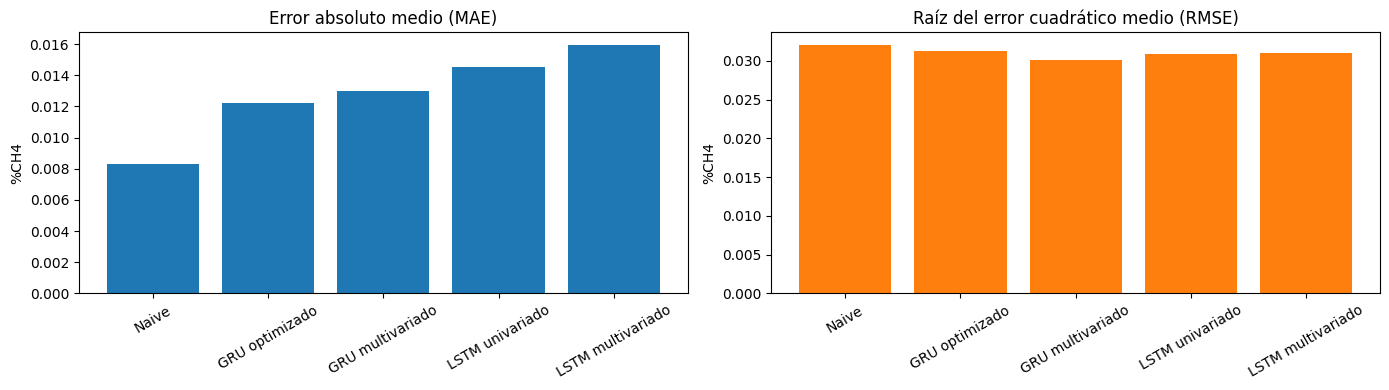

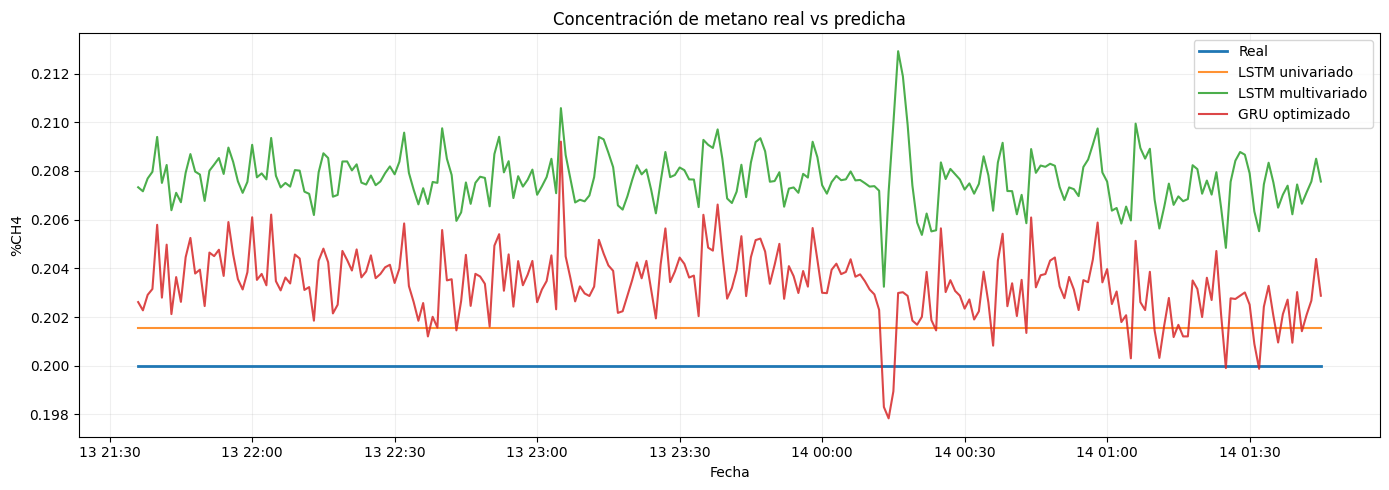

In [15]:
# ============================================================
# 15. Gráficas de comparación
# ============================================================
fig, axes=plt.subplots(1,2,figsize=(14,4))
axes[0].bar(tabla_metricas['Modelo'],tabla_metricas['MAE'])
axes[0].set_title('Error absoluto medio (MAE)')
axes[0].set_ylabel('%CH4');axes[0].tick_params(axis='x',rotation=30)
axes[1].bar(tabla_metricas['Modelo'],tabla_metricas['RMSE'],color='tab:orange')
axes[1].set_title('Raíz del error cuadrático medio (RMSE)')
axes[1].set_ylabel('%CH4');axes[1].tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()

MUESTRAS=250
fechas_prueba=serie.index[i_test]
plt.figure(figsize=(14,5))
plt.plot(fechas_prueba[:MUESTRAS],real[:MUESTRAS],label='Real',lw=2)
for nombre in ['LSTM univariado','LSTM multivariado','GRU optimizado']:
    plt.plot(fechas_prueba[:MUESTRAS],predicciones[nombre][:MUESTRAS],
             label=nombre,alpha=0.85)
plt.title('Concentración de metano real vs predicha')
plt.ylabel('%CH4');plt.xlabel('Fecha');plt.legend();plt.grid(alpha=0.2)
plt.tight_layout();plt.show()

In [16]:
# ============================================================
# 16. Interpretación automática de resultados
# ============================================================
ganador=tabla_metricas.iloc[0]
error_base=tabla_metricas.loc[tabla_metricas['Modelo']=='Naive','MAE'].iloc[0]
error_opt=tabla_metricas.loc[tabla_metricas['Modelo']=='GRU optimizado','MAE'].iloc[0]
mejora=100*(error_base-error_opt)/error_base if error_base else np.nan

print('RESULTADOS DEL EXPERIMENTO')
print(f"El menor MAE lo obtuvo: {ganador['Modelo']} ({ganador['MAE']:.5f} %CH4).")
print(f'El GRU optimizado cambió el MAE respecto al baseline en {mejora:.2f} %.')
if mejora > 0:
    print('En este conjunto, el GRU optimizado superó la referencia ingenua.')
else:
    print('En este conjunto, el GRU optimizado NO superó la referencia ingenua.')
print('Estos resultados dependen de los datos procesados y de la ejecución del entrenamiento.')

RESULTADOS DEL EXPERIMENTO
El menor MAE lo obtuvo: Naive (0.00832 %CH4).
El GRU optimizado cambió el MAE respecto al baseline en -47.17 %.
En este conjunto, el GRU optimizado NO superó la referencia ingenua.
Estos resultados dependen de los datos procesados y de la ejecución del entrenamiento.


In [17]:
# ============================================================
# 17. Exportación de métricas y modelos
# ============================================================
tabla_metricas.to_csv('metricas_mineria_metano.csv',index=False)
resultados_busqueda.to_csv('optimizacion_gru_mineria.csv',index=False)
modelo_uni.save('lstm_univariado_metano.keras')
modelo_multi_lstm.save('lstm_multivariado_metano.keras')
modelo_multi_gru.save('gru_multivariado_metano.keras')
mejor_gru.save('gru_optimizado_metano.keras')
print('Archivos exportados correctamente.')

Archivos exportados correctamente.


## 7. Conclusiones y recomendaciones

Al finalizar la ejecución se analizan las métricas y las gráficas obtenidas. Se consideran los siguientes aspectos:

1. Se identifica el modelo con menor MAE y RMSE en prueba.
2. Se determina si la incorporación de la velocidad del aire mejora o empeora el pronóstico respecto al modelo univariado.
3. Se comprueba si el mejor modelo supera la predicción de referencia.
4. Se describe la configuración de unidades, Dropout y tasa de aprendizaje seleccionada mediante validación.

**Limitaciones:** se utiliza una sección cronológica del dataset para hacer viable el ejercicio y las lecturas se agregan por minuto. No se evalúa un sistema real de alarmas. Los modelos no deben utilizarse para decisiones operativas de seguridad sin validación especializada; la predicción de eventos extremos requeriría un análisis adicional.

**Referencias:**

- Sikora, M., & Wróbel, Ł. (2021). *Methane* [Dataset]. Mendeley Data. https://doi.org/10.17632/yd7vw4c5mk.1
- Kozielski, M., Sikora, M., & Wróbel, Ł. (2021). *Data on methane concentration collected by underground coal mine sensors*. Data in Brief, 39, 107457. https://doi.org/10.1016/j.dib.2021.107457
